# 07 — Avaliação de desempenho no conjunto de teste

**TCC UNIP 2026** · Etapa 7 de 9 do pipeline · Seção 4.5.7 do trabalho escrito.

**Objetivo:** calcular as métricas por classe, as matrizes de confusão e as curvas ROC dos modelos finais.

**Entradas:**
- `modelo_resnet50.pt`, `modelo_efficientnet_b0.pt` e `config_final.json` (notebook 06)
- `test.csv` e imagens de teste (notebook 03)

**Saídas:**
- `avaliacao/` (métricas por classe, matrizes de confusão, curvas ROC, `comparacao_geral.csv`, `avaliacao_completa.json`)

Antes de executar: no Colab, selecione *Ambiente de execução → Alterar tipo de ambiente de execução → GPU* (necessário a partir do notebook 05). As saídas exibidas foram preservadas da execução original do notebook único.

In [ ]:
# Parâmetro: True usa o Google Drive para guardar os arquivos entre notebooks;
# False usa só o disco da sessão atual. Quando o notebook é executado pelo
# 00_executar_todos.ipynb, vale o valor definido lá.
if "USAR_DRIVE" not in globals():
    USAR_DRIVE = True


In [ ]:
# ============================================================
# PERSISTÊNCIA ENTRE NOTEBOOKS (Google Drive)
# ============================================================
# Cada notebook roda em uma sessão própria do Colab. Para que os arquivos gerados por um
# notebook fiquem disponíveis para os seguintes, a pasta /content/data é ligada a uma
# pasta no Google Drive. O valor de USAR_DRIVE é definido na célula anterior.
PASTA_DRIVE = "/content/drive/MyDrive/TCC_UNIP/data"

import os
if USAR_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    os.makedirs(PASTA_DRIVE, exist_ok=True)
    if not os.path.islink("/content/data"):
        if os.path.isdir("/content/data"):
            if os.listdir("/content/data"):
                raise RuntimeError("/content/data já contém arquivos: mova-os para a pasta do Drive antes de continuar.")
            os.rmdir("/content/data")
        os.symlink(PASTA_DRIVE, "/content/data")
print("Pasta de dados:", os.path.realpath("/content/data"))


## Funções do pipeline de dados (reutilizadas do notebook 04)

In [ ]:
# [Célula reutilizada de 03_preprocessamento.ipynb]
import os
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from tqdm import tqdm


In [ ]:
# [Célula reutilizada de 03_preprocessamento.ipynb]
SEED = 42
PROPORCAO_TREINO = 0.70
PROPORCAO_VAL = 0.15
PROPORCAO_TESTE = 0.15

# Mantido por compatibilidade com a estrutura original. Na versão corrigida, imagens sem
# lesion_id são mantidas e viram grupos próprios, salvo quando ligadas por pHash a duplicatas.
INCLUIR_SEM_LESION_ID = True

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
import pandas as pd
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
SAIDA_BASE = "/content/data/processed"
MEAN_IMAGENET = [0.485, 0.456, 0.406]
STD_IMAGENET = [0.229, 0.224, 0.225]
BATCH_SIZE = 32
NUM_WORKERS = 2   # o Colab tem 2 CPUs; mais workers que isso só atrapalha (ver aviso do DataLoader)

# Modo de teste rápido (opcional): use p.ex. 0.05 para treinar/avaliar com ~5% das imagens
# e conferir se o notebook inteiro roda, antes de gastar horas de GPU. None = usa tudo.
FRACAO_DADOS_DEBUG = None

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
# ============================================================
# TRANSFORMS
# ============================================================
# ATENÇÃO (teste de cor): o ColorJitter do Albumentations, quando 'hue' não é informado, aplica
# uma rotação de MATIZ por padrão (nas versões 2.x: até ±0.5 do círculo cromático, i.e. qualquer cor).
# Isso muda a cor da lesão — um sinal clínico central (critério "C" do ABCDE) — em metade das imagens.
# Esta é a configuração da versão anterior e é mantida como variante "original" para comparação.
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.3),
    A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
    ToTensorV2(),
])

# Val/teste: SEM augmentation aleatório — só normalização, para avaliação justa e reprodutível
eval_transform = A.Compose([
    A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
    ToTensorV2(),
])

# ------------------------------------------------------------
# Variantes de augmentation de COR (usadas no "Teste de alterações de cor")
#   "original"         -> a configuração acima (brilho, contraste, saturação E matiz padrão do Albumentations)
#   "brilho_contraste" -> só brilho e contraste (±20%); saturação e matiz FIXOS (cor da lesão preservada)
#   "sem_cor"          -> nenhuma alteração de cor (só flips/rotações/escala)
# ------------------------------------------------------------
def construir_train_transform(variante_cor="original"):
    if variante_cor == "original":
        return train_transform
    if variante_cor == "brilho_contraste":
        cor = [A.ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2),
                             saturation=(1.0, 1.0), hue=(0.0, 0.0), p=0.5)]
    elif variante_cor == "sem_cor":
        cor = []
    else:
        raise ValueError(f"Variante de cor desconhecida: {variante_cor}")
    return A.Compose([
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.RandomRotate90(p=0.5),
        *cor,
        A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=15, p=0.3),
        A.Normalize(mean=MEAN_IMAGENET, std=STD_IMAGENET),
        ToTensorV2(),
    ])

TRAIN_TRANSFORMS = {v: construir_train_transform(v)
                    for v in ["original", "brilho_contraste", "sem_cor"]}

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
# ============================================================
# DATASET
# ============================================================
from PIL import Image, ImageEnhance

def aplicar_perturbacao_cor(img_rgb, brilho=0.0, contraste=0.0, saturacao=0.0, matiz=0.0):
    """Perturbação DETERMINÍSTICA de cor (usada só na avaliação de robustez, nunca no treino).
    brilho/contraste/saturacao: variação relativa (0.2 = +20%, -0.2 = -20%).
    matiz: fração do círculo cromático (0.1 = 36 graus)."""
    pil = Image.fromarray(img_rgb)
    if brilho:
        pil = ImageEnhance.Brightness(pil).enhance(1.0 + brilho)
    if contraste:
        pil = ImageEnhance.Contrast(pil).enhance(1.0 + contraste)
    if saturacao:
        pil = ImageEnhance.Color(pil).enhance(1.0 + saturacao)
    if matiz:
        h, s, v = pil.convert("HSV").split()
        deslocamento = int(round(matiz * 255))
        h = h.point(lambda x: (x + deslocamento) % 256)
        pil = Image.merge("HSV", (h, s, v)).convert("RGB")
    return np.array(pil)


class DermatoDataset(Dataset):
    def __init__(self, dataframe, mapa_classes, transform=None, perturbacao=None):
        self.df = dataframe.reset_index(drop=True)
        self.mapa_classes = mapa_classes
        self.transform = transform
        self.perturbacao = perturbacao   # dict p/ aplicar_perturbacao_cor (None = sem perturbação)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        linha = self.df.iloc[idx]
        img = cv2.imread(linha["caminho_processado"])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        if self.perturbacao:
            img = aplicar_perturbacao_cor(img, **self.perturbacao)

        if self.transform:
            img = self.transform(image=img)["image"]

        rotulo = self.mapa_classes[linha["classe"]]
        return img, rotulo

In [ ]:
# [Célula reutilizada de 04_pipeline_dados_pytorch.ipynb]
# ============================================================
# CRIAÇÃO DOS DATALOADERS
# ============================================================
# Qual versão das imagens é usada por padrão: "com_dullrazor" (train.csv...) ou "sem_dullrazor".
# A célula de seleção da configuração final (mais adiante) atualiza este valor.
DADOS_ATIVOS = "com_dullrazor"

def caminho_csv_split(split, dados):
    sufixo = "" if dados == "com_dullrazor" else f"_{dados}"
    return f"{SAIDA_BASE}/{split}{sufixo}.csv"

def _ler_split(split, dados):
    df = pd.read_csv(caminho_csv_split(split, dados), low_memory=False)
    if FRACAO_DADOS_DEBUG:
        df = (df.groupby("classe", group_keys=False)
                .apply(lambda g: g.sample(n=max(2, int(len(g) * FRACAO_DADOS_DEBUG)),
                                          random_state=SEED)
                       if len(g) > 2 else g))
    return df

def criar_dataloaders(batch_size=BATCH_SIZE, dados=None, variante_cor="original"):
    dados = dados or DADOS_ATIVOS
    df_treino = _ler_split("train", dados)
    df_val = _ler_split("val", dados)
    df_teste = _ler_split("test", dados)

    classes_ordenadas = sorted(df_treino["classe"].unique())
    mapa_classes = {nome: idx for idx, nome in enumerate(classes_ordenadas)}
    print("Mapa de classes:", mapa_classes)
    print(f"Dados: {dados} | augmentation de cor: {variante_cor}")

    ds_treino = DermatoDataset(df_treino, mapa_classes, transform=TRAIN_TRANSFORMS[variante_cor])
    ds_val = DermatoDataset(df_val, mapa_classes, transform=eval_transform)
    ds_teste = DermatoDataset(df_teste, mapa_classes, transform=eval_transform)

    pin = torch.cuda.is_available()
    train_loader = DataLoader(ds_treino, batch_size=batch_size, shuffle=True,
                               num_workers=NUM_WORKERS, pin_memory=pin,
                               persistent_workers=NUM_WORKERS > 0)
    val_loader = DataLoader(ds_val, batch_size=batch_size, shuffle=False,
                             num_workers=NUM_WORKERS, pin_memory=pin)
    test_loader = DataLoader(ds_teste, batch_size=batch_size, shuffle=False,
                              num_workers=NUM_WORKERS, pin_memory=pin)

    return train_loader, val_loader, test_loader, mapa_classes


def criar_loader_teste(dados=None, perturbacao=None, batch_size=BATCH_SIZE):
    """DataLoader de TESTE (sem augmentation), opcionalmente com perturbação determinística
    de cor — usado na avaliação de robustez a brilho/contraste."""
    dados = dados or DADOS_ATIVOS
    df_treino = _ler_split("train", dados)
    mapa_classes = {n: i for i, n in enumerate(sorted(df_treino["classe"].unique()))}
    ds = DermatoDataset(_ler_split("test", dados), mapa_classes,
                        transform=eval_transform, perturbacao=perturbacao)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS,
                        pin_memory=torch.cuda.is_available())
    return loader, mapa_classes

In [ ]:
# ============================================================
# VERSÃO DAS IMAGENS DEFINIDA NA CONFIGURAÇÃO FINAL (06_treinamento_fine_tuning.ipynb)
# ============================================================
import json
_caminho_cfg = os.path.join(SAIDA_BASE, "experimentos", "config_final.json")
if os.path.exists(_caminho_cfg):
    with open(_caminho_cfg) as f:
        DADOS_ATIVOS = json.load(f)["config_final"]["dados"]
print("Versão das imagens utilizada:", DADOS_ATIVOS)


### AVALIAÇÃO COM MÉTRICAS CLÍNICAS + MATRIZ DE CONFUSÃO

Carrega os checkpoints já treinados (modelo_resnet50.pt, modelo_efficientnet_b0.pt)
e gera um pacote completo de avaliação, pronto para uso no Capítulo 4 (Resultados)
do TCC:

  - Matriz de confusão (heatmap) por arquitetura
  - Curvas ROC por classe (one-vs-rest) por arquitetura
  - Tabela de métricas clínicas por classe: sensibilidade, especificidade,
    precisão, F1-score
  - Tabela comparativa geral entre arquiteturas
  - Gráfico de barras comparando as arquiteturas
  - Tudo salvo em /content/data/processed/avaliacao/

Pré-requisito: rodar fine_tuning_completo.py antes (precisa dos checkpoints
e do dataset_pytorch.py disponível).

In [ ]:
import os
import json
import torch
import torch.nn as nn
from torchvision import models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

In [ ]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SAIDA_BASE = "/content/data/processed"
SAIDA_AVALIACAO = os.path.join(SAIDA_BASE, "avaliacao")
os.makedirs(SAIDA_AVALIACAO, exist_ok=True)

ARQUITETURAS = ["resnet50", "efficientnet_b0"]

In [ ]:
# ============================================================
# RECONSTRUÇÃO DO MODELO E CARREGAMENTO DO CHECKPOINT
# ============================================================
def carregar_modelo(arquitetura, num_classes):
    if arquitetura == "resnet50":
        modelo = models.resnet50(weights=None)
        modelo.fc = nn.Linear(modelo.fc.in_features, num_classes)
    elif arquitetura == "efficientnet_b0":
        modelo = models.efficientnet_b0(weights=None)
        modelo.classifier[1] = nn.Linear(modelo.classifier[1].in_features, num_classes)
    else:
        raise ValueError(f"Arquitetura não suportada: {arquitetura}")

    caminho_checkpoint = os.path.join(SAIDA_BASE, f"modelo_{arquitetura}.pt")
    modelo.load_state_dict(torch.load(caminho_checkpoint, map_location=DEVICE))
    modelo.to(DEVICE)
    modelo.eval()
    return modelo

In [ ]:
# ============================================================
# COLETA DE PREDIÇÕES NO CONJUNTO DE TESTE
# ============================================================
def coletar_predicoes(modelo, test_loader):
    todos_rotulos, todas_probs, todas_preds = [], [], []

    with torch.no_grad():
        for imagens, rotulos in test_loader:
            imagens = imagens.to(DEVICE)
            saidas = modelo(imagens)
            probs = torch.softmax(saidas, dim=1).cpu().numpy()
            preds = np.argmax(probs, axis=1)

            todos_rotulos.extend(rotulos.numpy())
            todas_probs.extend(probs)
            todas_preds.extend(preds)

    return np.array(todos_rotulos), np.array(todas_probs), np.array(todas_preds)

In [ ]:
# ============================================================
# MATRIZ DE CONFUSÃO (HEATMAP)
# ============================================================
def plotar_matriz_confusao(rotulos_verdadeiros, predicoes, nomes_classes, arquitetura):
    matriz = confusion_matrix(rotulos_verdadeiros, predicoes)
    matriz_normalizada = matriz.astype("float") / matriz.sum(axis=1, keepdims=True)

    fig, eixos = plt.subplots(1, 2, figsize=(18, 7))

    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues",
                xticklabels=nomes_classes, yticklabels=nomes_classes, ax=eixos[0])
    eixos[0].set_title(f"Matriz de Confusão (contagem) — {arquitetura}")
    eixos[0].set_xlabel("Predito")
    eixos[0].set_ylabel("Verdadeiro")
    eixos[0].tick_params(axis="x", rotation=45)

    sns.heatmap(matriz_normalizada, annot=True, fmt=".2f", cmap="Blues",
                xticklabels=nomes_classes, yticklabels=nomes_classes, ax=eixos[1])
    eixos[1].set_title(f"Matriz de Confusão (normalizada por classe) — {arquitetura}")
    eixos[1].set_xlabel("Predito")
    eixos[1].set_ylabel("Verdadeiro")
    eixos[1].tick_params(axis="x", rotation=45)

    plt.tight_layout()
    caminho = os.path.join(SAIDA_AVALIACAO, f"matriz_confusao_{arquitetura}.png")
    plt.savefig(caminho, dpi=150)
    plt.show()
    print(f"Matriz de confusão salva em: {caminho}")

    return matriz

In [ ]:
# ============================================================
# CURVAS ROC POR CLASSE (ONE-VS-REST)
# ============================================================
def plotar_curvas_roc(rotulos_verdadeiros, probs, nomes_classes, arquitetura):
    num_classes = len(nomes_classes)
    rotulos_binarizados = label_binarize(rotulos_verdadeiros, classes=range(num_classes))

    plt.figure(figsize=(9, 7))
    valores_auc = {}

    for i, nome_classe in enumerate(nomes_classes):
        fpr, tpr, _ = roc_curve(rotulos_binarizados[:, i], probs[:, i])
        valor_auc = auc(fpr, tpr)
        valores_auc[nome_classe] = valor_auc
        plt.plot(fpr, tpr, label=f"{nome_classe} (AUC = {valor_auc:.3f})")

    plt.plot([0, 1], [0, 1], "k--", label="Aleatório (AUC = 0.5)")
    plt.xlabel("Taxa de Falso Positivo (1 - Especificidade)")
    plt.ylabel("Taxa de Verdadeiro Positivo (Sensibilidade)")
    plt.title(f"Curvas ROC por classe (one-vs-rest) — {arquitetura}")
    plt.legend(loc="lower right", fontsize=8)
    plt.tight_layout()

    caminho = os.path.join(SAIDA_AVALIACAO, f"curvas_roc_{arquitetura}.png")
    plt.savefig(caminho, dpi=150)
    plt.show()
    print(f"Curvas ROC salvas em: {caminho}")

    return valores_auc

In [ ]:
# ============================================================
# MÉTRICAS CLÍNICAS POR CLASSE
# ============================================================
def calcular_metricas_clinicas_por_classe(matriz, nomes_classes, valores_auc):
    linhas = []
    total = matriz.sum()

    for i, nome_classe in enumerate(nomes_classes):
        vp = matriz[i, i]
        fn = matriz[i, :].sum() - vp
        fp = matriz[:, i].sum() - vp
        vn = total - vp - fn - fp

        sensibilidade = vp / (vp + fn) if (vp + fn) > 0 else 0.0   # recall / taxa de detecção
        especificidade = vn / (vn + fp) if (vn + fp) > 0 else 0.0  # taxa de rejeição correta
        precisao = vp / (vp + fp) if (vp + fp) > 0 else 0.0        # valor preditivo positivo
        vpn = vn / (vn + fn) if (vn + fn) > 0 else 0.0             # valor preditivo negativo
        f1 = (2 * precisao * sensibilidade / (precisao + sensibilidade)
              if (precisao + sensibilidade) > 0 else 0.0)

        linhas.append({
            "classe": nome_classe,
            "n_amostras_teste": int(matriz[i, :].sum()),
            "sensibilidade": round(sensibilidade, 4),
            "especificidade": round(especificidade, 4),
            "precisao_vpp": round(precisao, 4),
            "vpn": round(vpn, 4),
            "f1_score": round(f1, 4),
            "auc_roc": round(valores_auc[nome_classe], 4),
        })

    return pd.DataFrame(linhas)

In [ ]:
# ============================================================
# AVALIAÇÃO COMPLETA DE UMA ARQUITETURA
# ============================================================
def avaliar_arquitetura(arquitetura, test_loader, mapa_classes):
    print("\n" + "=" * 60)
    print(f"Avaliando: {arquitetura}")
    print("=" * 60)

    nomes_classes = sorted(mapa_classes, key=lambda k: mapa_classes[k])
    num_classes = len(nomes_classes)

    modelo = carregar_modelo(arquitetura, num_classes)
    rotulos_verdadeiros, probs, predicoes = coletar_predicoes(modelo, test_loader)

    matriz = plotar_matriz_confusao(rotulos_verdadeiros, predicoes, nomes_classes, arquitetura)
    valores_auc = plotar_curvas_roc(rotulos_verdadeiros, probs, nomes_classes, arquitetura)
    df_metricas = calcular_metricas_clinicas_por_classe(matriz, nomes_classes, valores_auc)

    print(f"\nMétricas clínicas por classe — {arquitetura}:")
    print(df_metricas.to_string(index=False))

    caminho_csv = os.path.join(SAIDA_AVALIACAO, f"metricas_por_classe_{arquitetura}.csv")
    df_metricas.to_csv(caminho_csv, index=False)
    print(f"\nTabela salva em: {caminho_csv}")

    acuracia_geral = (predicoes == rotulos_verdadeiros).mean()
    acuracia_balanceada = float(df_metricas["sensibilidade"].mean())
    resumo_geral = {
        "arquitetura": arquitetura,
        "acuracia_geral": round(float(acuracia_geral), 4),
        "acuracia_balanceada": round(acuracia_balanceada, 4),
        "sensibilidade_media_macro": round(float(df_metricas["sensibilidade"].mean()), 4),
        "especificidade_media_macro": round(float(df_metricas["especificidade"].mean()), 4),
        "precisao_media_macro": round(float(df_metricas["precisao_vpp"].mean()), 4),
        "f1_medio_macro": round(float(df_metricas["f1_score"].mean()), 4),
        "auc_roc_media_macro": round(float(df_metricas["auc_roc"].mean()), 4),
    }

    del modelo
    torch.cuda.empty_cache()

    return df_metricas, resumo_geral

In [ ]:
# ============================================================
# COMPARAÇÃO VISUAL ENTRE ARQUITETURAS
# ============================================================
def plotar_comparacao_arquiteturas(resumos):
    df_resumo = pd.DataFrame(resumos)
    metricas_plotadas = [
        "acuracia_geral", "sensibilidade_media_macro", "especificidade_media_macro",
        "precisao_media_macro", "f1_medio_macro", "auc_roc_media_macro"
    ]

    df_plot = df_resumo.melt(
        id_vars="arquitetura", value_vars=metricas_plotadas,
        var_name="metrica", value_name="valor"
    )

    plt.figure(figsize=(12, 6))
    sns.barplot(data=df_plot, x="metrica", y="valor", hue="arquitetura")
    plt.title("Comparação geral entre arquiteturas (médias macro)")
    plt.xticks(rotation=30, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()

    caminho = os.path.join(SAIDA_AVALIACAO, "comparacao_arquiteturas.png")
    plt.savefig(caminho, dpi=150)
    plt.show()
    print(f"\nGráfico comparativo salvo em: {caminho}")

    return df_resumo

Carregando DataLoaders...
Mapa de classes: {'carcinoma_basocelular': 0, 'ceratose_actinica': 1, 'ceratose_seborreica': 2, 'dermatofibroma': 3, 'lesao_vascular': 4, 'melanoma': 5, 'nevo_melanocitico': 6}
Dados: com_dullrazor | augmentation de cor: original

Avaliando: resnet50


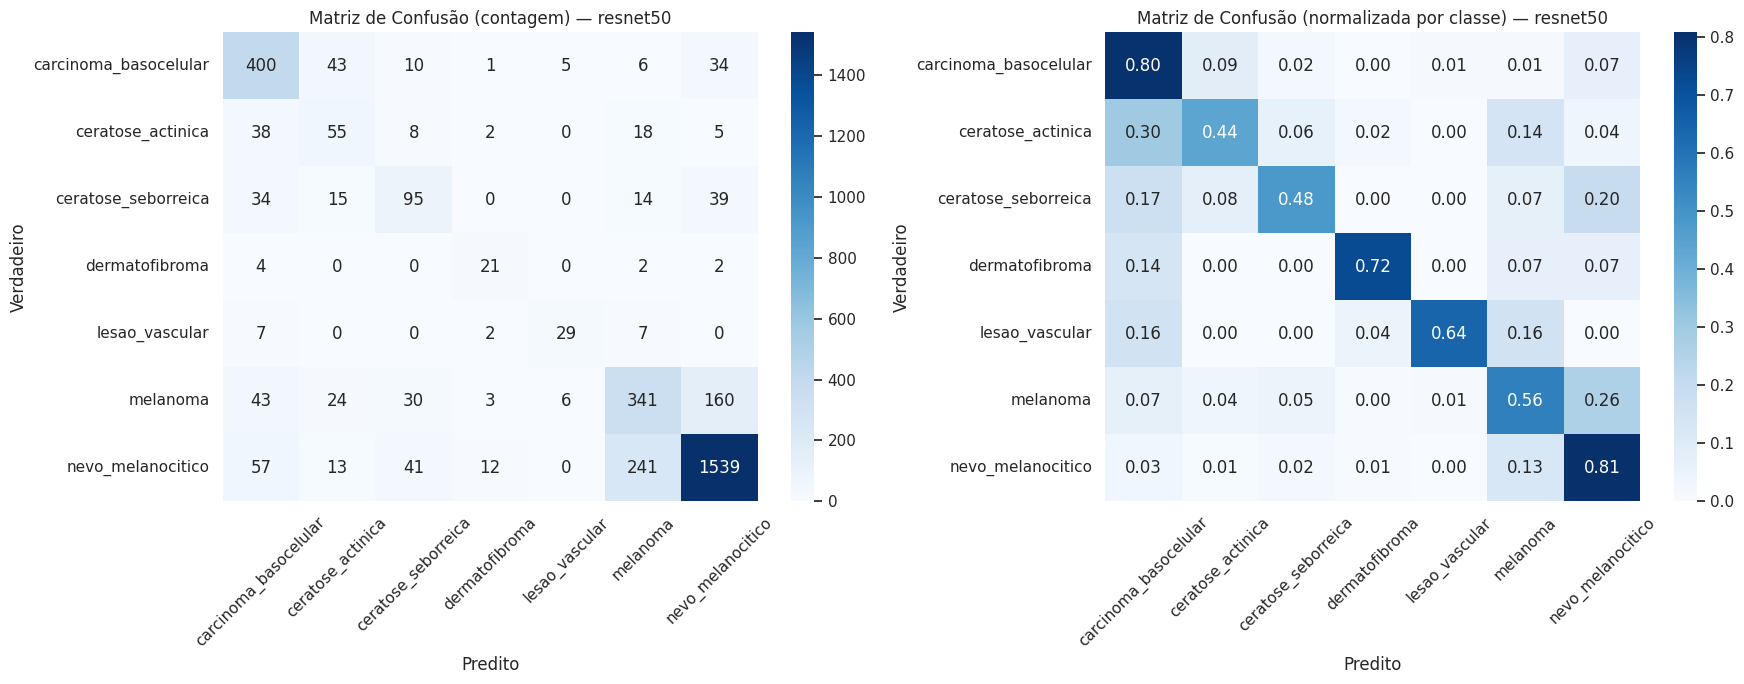

Matriz de confusão salva em: /content/data/processed/avaliacao/matriz_confusao_resnet50.png


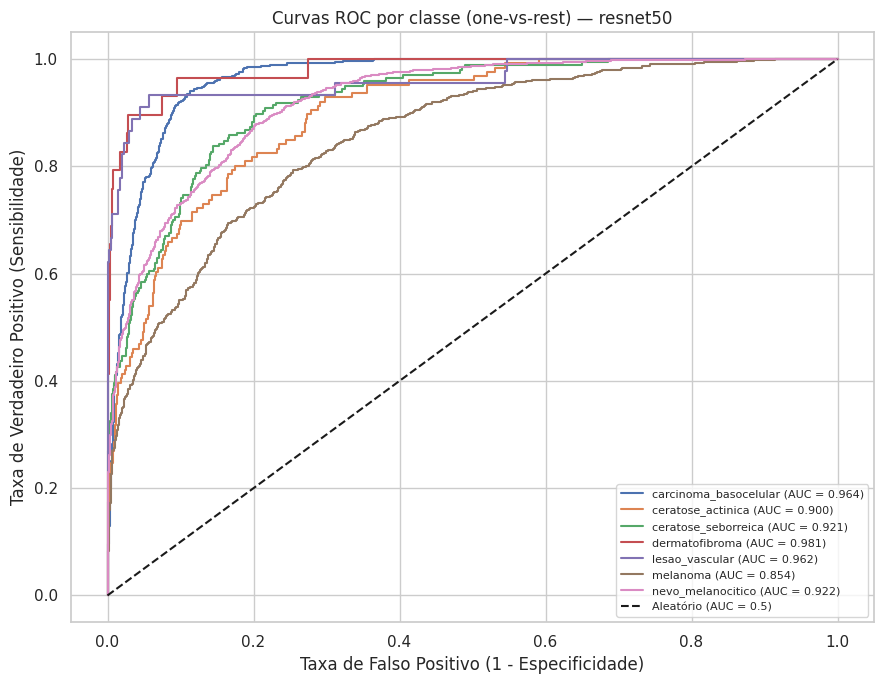

Curvas ROC salvas em: /content/data/processed/avaliacao/curvas_roc_resnet50.png

Métricas clínicas por classe — resnet50:
               classe  n_amostras_teste  sensibilidade  especificidade  precisao_vpp    vpn  f1_score  auc_roc
carcinoma_basocelular               499         0.8016          0.9370        0.6861 0.9649    0.7394   0.9636
    ceratose_actinica               126         0.4365          0.9710        0.3667 0.9782    0.3986   0.8997
  ceratose_seborreica               197         0.4822          0.9723        0.5163 0.9683    0.4987   0.9207
       dermatofibroma                29         0.7241          0.9941        0.5122 0.9976    0.6000   0.9806
       lesao_vascular                45         0.6444          0.9967        0.7250 0.9952    0.6824   0.9621
             melanoma               607         0.5618          0.8971        0.5421 0.9042    0.5518   0.8539
    nevo_melanocitico              1903         0.8087          0.8403        0.8651 0.7763    0.8360

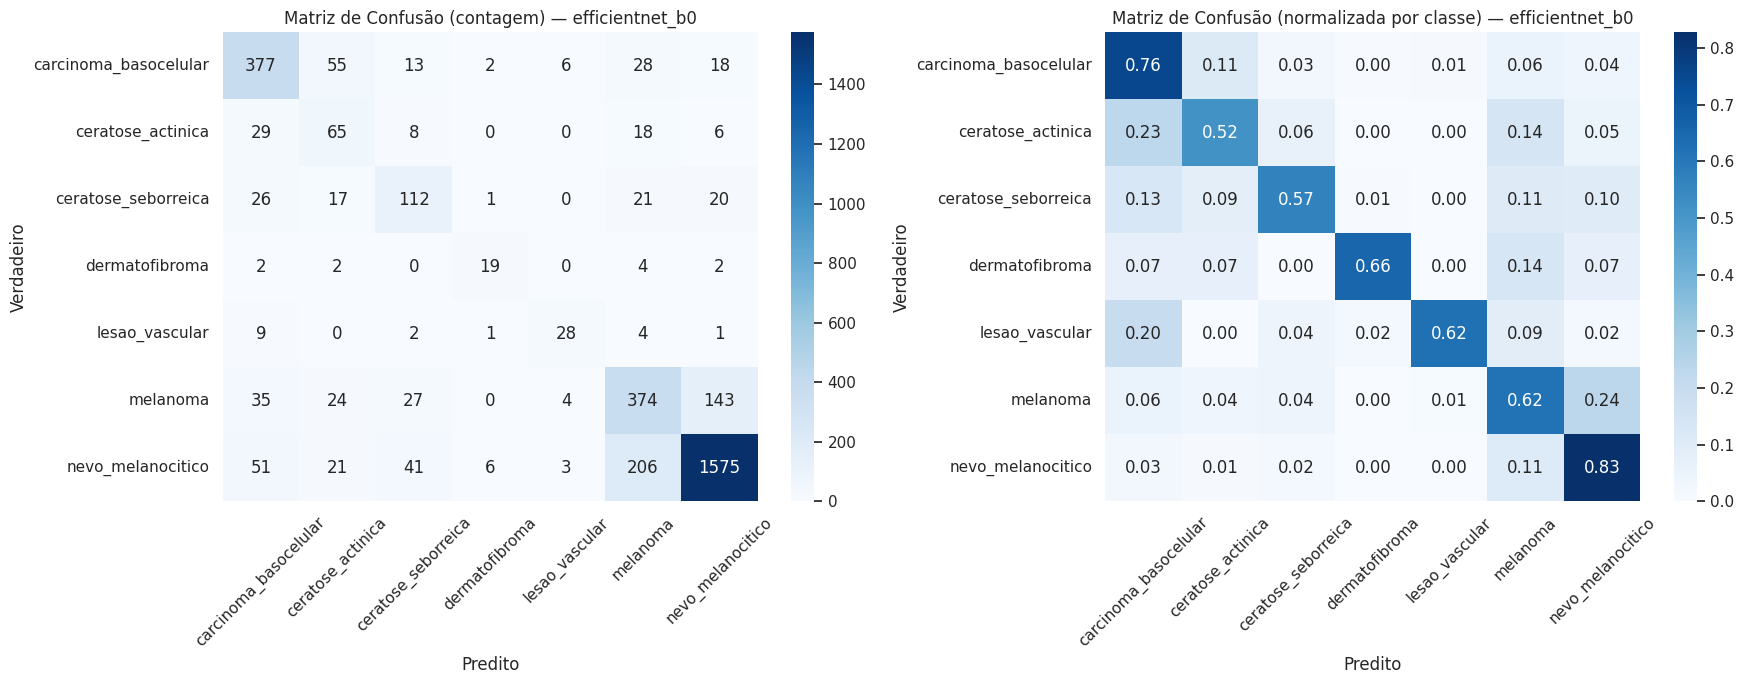

Matriz de confusão salva em: /content/data/processed/avaliacao/matriz_confusao_efficientnet_b0.png


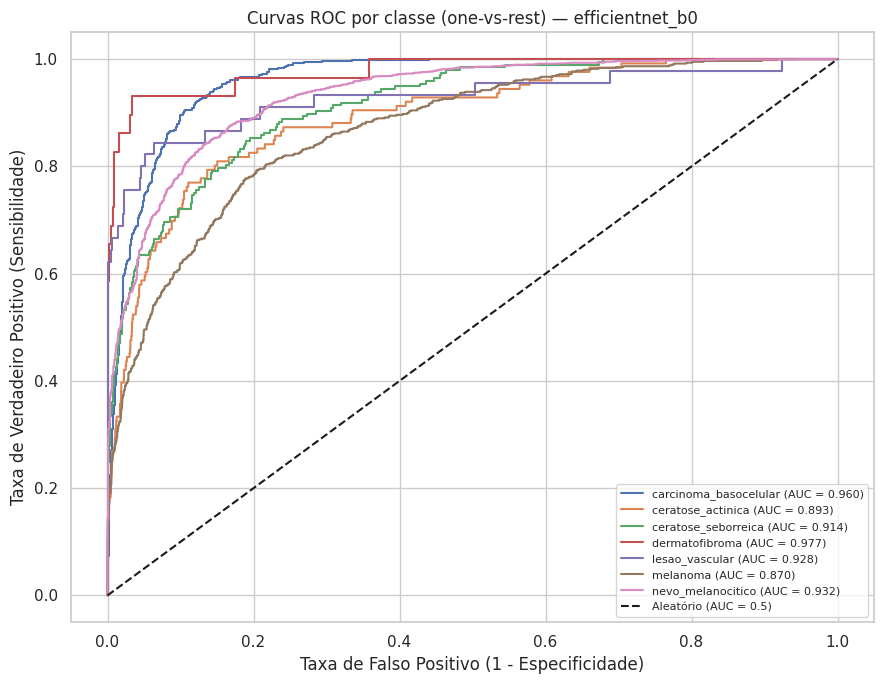

Curvas ROC salvas em: /content/data/processed/avaliacao/curvas_roc_efficientnet_b0.png

Métricas clínicas por classe — efficientnet_b0:
               classe  n_amostras_teste  sensibilidade  especificidade  precisao_vpp    vpn  f1_score  auc_roc
carcinoma_basocelular               499         0.7555          0.9477        0.7127 0.9576    0.7335   0.9603
    ceratose_actinica               126         0.5159          0.9637        0.3533 0.9811    0.4194   0.8929
  ceratose_seborreica               197         0.5685          0.9716        0.5517 0.9735    0.5600   0.9136
       dermatofibroma                29         0.6552          0.9970        0.6552 0.9970    0.6552   0.9772
       lesao_vascular                45         0.6222          0.9961        0.6829 0.9949    0.6512   0.9284
             melanoma               607         0.6161          0.8996        0.5710 0.9153    0.5927   0.8696
    nevo_melanocitico              1903         0.8276          0.8736        0.8924 0.

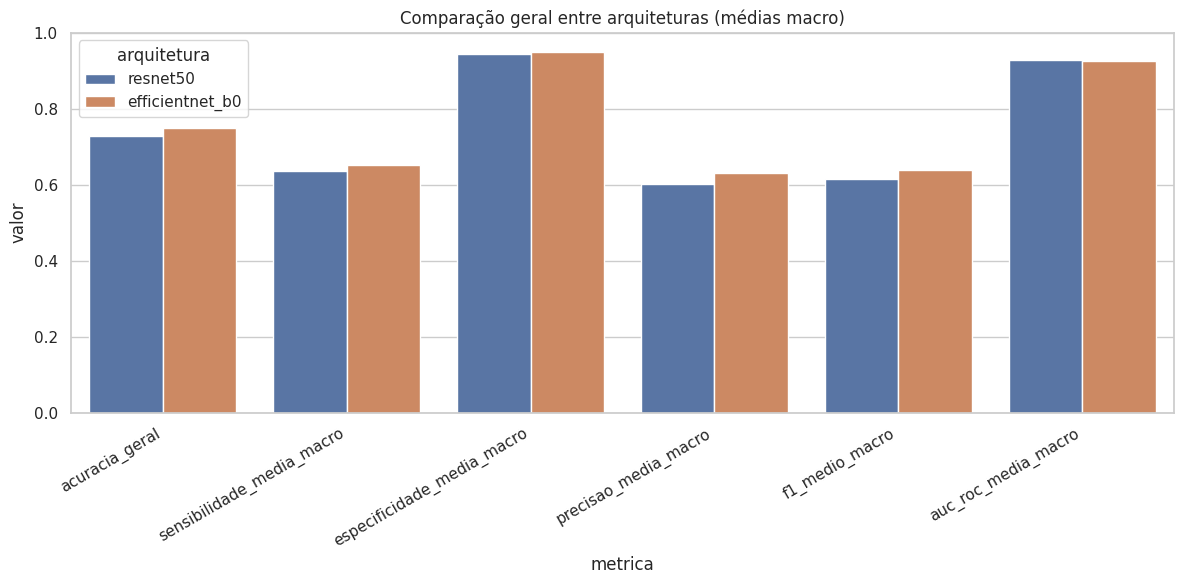


Gráfico comparativo salvo em: /content/data/processed/avaliacao/comparacao_arquiteturas.png
    arquitetura  acuracia_geral  acuracia_balanceada  sensibilidade_media_macro  especificidade_media_macro  precisao_media_macro  f1_medio_macro  auc_roc_media_macro
       resnet50          0.7281               0.6370                     0.6370                      0.9441                0.6019          0.6153               0.9289
efficientnet_b0          0.7487               0.6516                     0.6516                      0.9499                0.6313          0.6387               0.9249

Tabela comparativa salva em: /content/data/processed/avaliacao/comparacao_geral.csv
Avaliação completa consolidada em: /content/data/processed/avaliacao/avaliacao_completa.json

ARQUIVOS GERADOS EM: /content/data/processed/avaliacao
  - avaliacao_completa.json
  - comparacao_arquiteturas.png
  - comparacao_geral.csv
  - curvas_roc_efficientnet_b0.png
  - curvas_roc_resnet50.png
  - matriz_confusao_effi

In [ ]:
# ============================================================
# EXECUÇÃO
# ============================================================
if __name__ == "__main__":
    print("Carregando DataLoaders...")
    _, _, test_loader, mapa_classes = criar_dataloaders()

    resumos_gerais = []
    metricas_completas = {}

    for arquitetura in ARQUITETURAS:
        df_metricas, resumo = avaliar_arquitetura(arquitetura, test_loader, mapa_classes)
        resumos_gerais.append(resumo)
        metricas_completas[arquitetura] = df_metricas.to_dict(orient="records")

    print("\n" + "=" * 70)
    print("TABELA COMPARATIVA GERAL")
    print("=" * 70)
    df_comparacao = plotar_comparacao_arquiteturas(resumos_gerais)
    print(df_comparacao.to_string(index=False))

    caminho_comparacao_csv = os.path.join(SAIDA_AVALIACAO, "comparacao_geral.csv")
    df_comparacao.to_csv(caminho_comparacao_csv, index=False)
    print(f"\nTabela comparativa salva em: {caminho_comparacao_csv}")

    # Consolida tudo num único JSON para referência
    caminho_json = os.path.join(SAIDA_AVALIACAO, "avaliacao_completa.json")
    with open(caminho_json, "w") as f:
        json.dump({
            "resumo_geral": resumos_gerais,
            "metricas_por_classe": metricas_completas,
        }, f, indent=2)
    print(f"Avaliação completa consolidada em: {caminho_json}")

    print("\n" + "=" * 70)
    print("ARQUIVOS GERADOS EM:", SAIDA_AVALIACAO)
    print("=" * 70)
    for arquivo in sorted(os.listdir(SAIDA_AVALIACAO)):
        print(f"  - {arquivo}")

In [ ]:
# ============================================================
# RASCUNHO AUTOMÁTICO DA DISCUSSÃO A PARTIR DOS RESULTADOS REAIS
# ============================================================
# Este código não inventa conclusões: só gera um rascunho quando os JSONs existem.
# Revise o texto, confronte com os estudos do referencial e não interprete correlação como causalidade.

def gerar_rascunho_discussao():
    caminho = os.path.join(SAIDA_BASE, "resultados_comparacao.json")
    if not os.path.exists(caminho):
        print("Resultados finais ainda não encontrados. Execute o treinamento final antes da discussão.")
        return None
    with open(caminho, encoding="utf-8") as f:
        dados = json.load(f)
    resultados = dados.get("resultados", [])
    if len(resultados) < 2:
        print("O arquivo não contém resultados para as duas arquiteturas.")
        return None
    por_nome = {r.get("arquitetura"): r for r in resultados}
    if "resnet50" not in por_nome or "efficientnet_b0" not in por_nome:
        print("Não foi possível identificar ambas as arquiteturas no JSON.")
        return None
    r, e = por_nome["resnet50"], por_nome["efficientnet_b0"]
    metricas = ["acuracia_balanceada", "f1_macro", "sens_melanoma", "auc_roc_ovr"]
    linhas = ["RASCUNHO PARA REVISÃO — DISCUSSÃO DOS RESULTADOS", ""]
    linhas.append(f"A ResNet50 obteve acurácia balanceada de {r.get('acuracia_balanceada', float('nan')):.4f} e macro F1 de {r.get('f1_macro', float('nan')):.4f}; a EfficientNet-B0 obteve acurácia balanceada de {e.get('acuracia_balanceada', float('nan')):.4f} e macro F1 de {e.get('f1_macro', float('nan')):.4f}.")
    chave = "acuracia_balanceada" if r.get("acuracia_balanceada") is not None and e.get("acuracia_balanceada") is not None else "f1_macro"
    melhor = "ResNet50" if (r.get(chave, -1) or -1) >= (e.get(chave, -1) or -1) else "EfficientNet-B0"
    linhas.append(f"Considerando {chave} como critério principal de comparação, a maior pontuação foi observada em {melhor}. Essa conclusão deve ser contextualizada pelas métricas por classe, e não apenas pela métrica agregada.")
    linhas.append(f"A sensibilidade para melanoma foi {r.get('sens_melanoma', float('nan')):.4f} na ResNet50 e {e.get('sens_melanoma', float('nan')):.4f} na EfficientNet-B0. O modelo com maior sensibilidade para melanoma foi {('ResNet50' if (r.get('sens_melanoma') or -1) >= (e.get('sens_melanoma') or -1) else 'EfficientNet-B0')}; isso deve ser discutido em conjunto com os falsos negativos e a especificidade.")
    linhas.append("As classes com maior confusão devem ser identificadas nas matrizes de confusão salvas. Relacione os erros às quantidades por classe e às métricas de sensibilidade/F1, evitando atribuir o efeito exclusivamente ao desbalanceamento sem evidência adicional.")
    linhas.append("A influência de DullRazor e Focal Loss deve ser descrita a partir do arquivo experimentos/ablation_tcc_quatro_cenarios.csv. Compare acurácia balanceada, macro F1 e sensibilidade de melanoma e informe que os experimentos de ablação usam o mesmo particionamento e número de épocas.")
    linhas.append("Por fim, confronte os resultados com os trabalhos citados no referencial teórico. Não declare concordância ou superioridade frente à literatura sem comparação explícita de bases, particionamento, classes, métricas e protocolo experimental.")
    texto = "\n\n".join(linhas)
    caminho_txt = os.path.join(SAIDA_BASE, "rascunho_discussao_resultados.txt")
    with open(caminho_txt, "w", encoding="utf-8") as f:
        f.write(texto)
    print(texto)
    print(f"\nRascunho salvo em: {caminho_txt}")
    return texto

if __name__ == "__main__":
    gerar_rascunho_discussao()


RASCUNHO PARA REVISÃO — DISCUSSÃO DOS RESULTADOS



A ResNet50 obteve acurácia balanceada de 0.6369 e macro F1 de 0.6153; a EfficientNet-B0 obteve acurácia balanceada de 0.6487 e macro F1 de 0.6370.

Considerando acuracia_balanceada como critério principal de comparação, a maior pontuação foi observada em EfficientNet-B0. Essa conclusão deve ser contextualizada pelas métricas por classe, e não apenas pela métrica agregada.

A sensibilidade para melanoma foi 0.5601 na ResNet50 e 0.6145 na EfficientNet-B0. O modelo com maior sensibilidade para melanoma foi EfficientNet-B0; isso deve ser discutido em conjunto com os falsos negativos e a especificidade.

As classes com maior confusão devem ser identificadas nas matrizes de confusão salvas. Relacione os erros às quantidades por classe e às métricas de sensibilidade/F1, evitando atribuir o efeito exclusivamente ao desbalanceamento sem evidência adicional.

A influência de DullRazor e Focal Loss deve ser descrita a partir do arquivo experimen